In [ ]:
# Drone-Based Potato Late Blight Detection: Prototype


In [1]:
!pip -q install torch torchvision scikit-learn matplotlib pillow
!mkdir -p src outputs data

In [3]:
!pip -q install kagglehub
import kagglehub, glob, os, shutil
path = kagglehub.dataset_download('emmarex/plantdisease')
print('downloaded to', path)
for d in glob.glob(os.path.join(path, '**', 'Potato___*'), recursive=True):
    if os.path.isdir(d):
        shutil.copytree(d, os.path.join('data', os.path.basename(d)), dirs_exist_ok=True)
print(os.listdir('data'))

Using Colab cache for faster access to the 'plantdisease' dataset.
downloaded to /kaggle/input/plantdisease
['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


In [4]:
import os
for c in sorted(os.listdir('data')):
    print(c, len(os.listdir(os.path.join('data', c))))

Potato___Early_blight 1000
Potato___Late_blight 1000
Potato___healthy 152


In [10]:
%%writefile src/train.py

import argparse, json, os
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from sklearn.metrics import classification_report, confusion_matrix, recall_score
from sklearn.model_selection import train_test_split
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def build_model(name, n_classes):
    if name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        for p in m.features[:4].parameters():       # freeze early layers
            p.requires_grad = False
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
    elif name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        for p in list(m.conv1.parameters()) + list(m.layer1.parameters()) + list(m.layer2.parameters()):
            p.requires_grad = False
        m.fc = nn.Linear(m.fc.in_features, n_classes)
    else:
        raise ValueError("model must be efficientnet_b0 or resnet18")
    return m


def evaluate(model, loader, device):
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            ps += model(x.to(device)).argmax(1).cpu().tolist()
            ys += y.tolist()
    return np.array(ys), np.array(ps)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", default="data")
    ap.add_argument("--model", default="efficientnet_b0")
    ap.add_argument("--epochs", type=int, default=8)
    ap.add_argument("--batch", type=int, default=32)
    ap.add_argument("--lr", type=float, default=1e-3)
    ap.add_argument("--out", default="outputs")
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--patience", type=int, default=10)      # NEW (1/3)
    a = ap.parse_args()
    os.makedirs(a.out, exist_ok=True)
    torch.manual_seed(a.seed); np.random.seed(a.seed)
    device = "cuda" if torch.cuda.is_available() else "cpu"

    train_tf = transforms.Compose([                       # augmentation
        transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(20), transforms.ColorJitter(0.2, 0.2, 0.2),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    eval_tf = transforms.Compose([
        transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

    full_train = datasets.ImageFolder(a.data_dir, transform=train_tf)
    full_eval = datasets.ImageFolder(a.data_dir, transform=eval_tf)
    classes = full_train.classes
    labels = np.array(full_train.targets)

    # 70 / 15 / 15 stratified split
    idx = np.arange(len(labels))
    tr, rest = train_test_split(idx, test_size=0.30, stratify=labels, random_state=a.seed)
    va, te = train_test_split(rest, test_size=0.50, stratify=labels[rest], random_state=a.seed)
    train_dl = DataLoader(Subset(full_train, tr), batch_size=a.batch, shuffle=True, num_workers=2)
    val_dl = DataLoader(Subset(full_eval, va), batch_size=a.batch, num_workers=2)
    test_dl = DataLoader(Subset(full_eval, te), batch_size=a.batch, num_workers=2)
    print(f"classes={classes}  train={len(tr)} val={len(va)} test={len(te)}  device={device}")

    # class-imbalance handling: weighted loss
    counts = np.bincount(labels[tr], minlength=len(classes))
    weights = torch.tensor(counts.sum() / (len(classes) * counts), dtype=torch.float32).to(device)
    loss_fn = nn.CrossEntropyLoss(weight=weights)

    model = build_model(a.model, len(classes)).to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=a.lr)

    best_recall, best_path = -1, os.path.join(a.out, "best_model.pt")
    bad = 0                                                   # NEW (2/3)
    for ep in range(a.epochs):
        model.train(); total = 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); opt.step()
            total += loss.item() * len(x)
        yv, pv = evaluate(model, val_dl, device)
        rec = recall_score(yv, pv, average="macro")       # select on validation recall
        print(f"epoch {ep+1}/{a.epochs}  loss={total/len(tr):.4f}  val_acc={(yv==pv).mean():.4f}  val_macro_recall={rec:.4f}")
        if rec > best_recall:                                 # NEW (3/3)
            best_recall = rec; bad = 0; torch.save(model.state_dict(), best_path)
        else:
            bad += 1
            if bad >= a.patience:
                print(f"Early stopping at epoch {ep+1} (no improvement for {a.patience} epochs)")
                break

    # final report ONCE on the untouched test set
    model.load_state_dict(torch.load(best_path, map_location=device))
    yt, pt = evaluate(model, test_dl, device)
    report = classification_report(yt, pt, target_names=classes, output_dict=True)
    print(classification_report(yt, pt, target_names=classes))
    json.dump({"classes": classes, "model": a.model, "report": report}, open(os.path.join(a.out, "metrics.json"), "w"), indent=2)

    cm = confusion_matrix(yt, pt)
    fig, ax = plt.subplots(figsize=(5, 4.5)); ax.imshow(cm, cmap="Greens")
    ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
    ax.set_xticklabels([c.split("___")[-1] for c in classes], rotation=30, ha="right")
    ax.set_yticklabels([c.split("___")[-1] for c in classes])
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test set)")
    fig.tight_layout(); fig.savefig(os.path.join(a.out, "confusion_matrix.png"), dpi=150)
    json.dump({"test_indices": [int(i) for i in te]}, open(os.path.join(a.out, "test_split.json"), "w"))


if __name__ == "__main__":
    main()

Overwriting src/train.py


In [6]:
%%writefile src/gradcam.py
"""Grad-CAM: shows which leaf regions the classifier looked at.

Run:  python src/gradcam.py --data_dir data --model efficientnet_b0 --n 6
(uses outputs/best_model.pt and outputs/test_split.json from train.py)
"""
import argparse, json, os
import numpy as np, torch
from torchvision import datasets, transforms
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from train import build_model, MEAN, STD


def gradcam(model, layer, x, cls=None):
    acts, grads = [], []
    h1 = layer.register_forward_hook(lambda m, i, o: acts.append(o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.append(go[0]))
    out = model(x); cls = int(out.argmax(1)) if cls is None else cls
    model.zero_grad(); out[0, cls].backward()
    h1.remove(); h2.remove()
    w = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * acts[0]).sum(1))[0].detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, cls, out.softmax(1)[0, cls].item()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", default="data"); ap.add_argument("--model", default="efficientnet_b0")
    ap.add_argument("--out", default="outputs"); ap.add_argument("--n", type=int, default=6)
    a = ap.parse_args()
    tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    ds = datasets.ImageFolder(a.data_dir, transform=tf)
    model = build_model(a.model, len(ds.classes))
    model.load_state_dict(torch.load(os.path.join(a.out, "best_model.pt"), map_location="cpu")); model.eval()
    layer = model.features[-1] if a.model == "efficientnet_b0" else model.layer4[-1]
    te = json.load(open(os.path.join(a.out, "test_split.json")))["test_indices"]
    pick = np.random.RandomState(0).choice(te, size=min(a.n, len(te)), replace=False)

    fig, axes = plt.subplots(2, len(pick), figsize=(3 * len(pick), 6))
    for k, i in enumerate(pick):
        x, y = ds[i]; cam, c, p = gradcam(model, layer, x.unsqueeze(0))
        img = x.permute(1, 2, 0).numpy() * STD + MEAN
        cam_big = np.array(transforms.functional.resize(
            transforms.functional.to_pil_image(torch.tensor(cam).unsqueeze(0).float()), (224, 224)))
        axes[0, k].imshow(np.clip(img, 0, 1)); axes[0, k].axis("off")
        axes[0, k].set_title(f"true: {ds.classes[y].split('___')[-1]}", fontsize=9)
        axes[1, k].imshow(np.clip(img, 0, 1)); axes[1, k].imshow(cam_big, cmap="jet", alpha=0.45); axes[1, k].axis("off")
        axes[1, k].set_title(f"pred: {ds.classes[c].split('___')[-1]} ({p:.2f})", fontsize=9)
    fig.tight_layout(); fig.savefig(os.path.join(a.out, "gradcam_examples.png"), dpi=150)
    print("saved", os.path.join(a.out, "gradcam_examples.png"))


if __name__ == "__main__":
    main()


Writing src/gradcam.py


In [7]:
%%writefile src/vegetation_indices.py

import numpy as np


def _nd(a, b):
    a, b = a.astype("float32"), b.astype("float32")
    return (a - b) / (a + b + 1e-8)


def ndvi(nir, red): return _nd(nir, red)
def ndre(nir, red_edge): return _nd(nir, red_edge)
def gndvi(nir, green): return _nd(nir, green)


def zone_means(index_map, rows=4, cols=4):
    """Average an index map over a rows x cols grid of field zones."""
    h, w = index_map.shape
    return np.array([[index_map[r*h//rows:(r+1)*h//rows, c*w//cols:(c+1)*w//cols].mean()
                      for c in range(cols)] for r in range(rows)])


if __name__ == "__main__":
    rng = np.random.RandomState(0)           # demo with synthetic bands
    nir, red = rng.uniform(0.4, 0.6, (64, 64)), rng.uniform(0.05, 0.15, (64, 64))
    nir[:32, :32] *= 0.6                      # simulate a stressed corner
    print("NDVI zone means:\n", zone_means(ndvi(nir, red)).round(2))


Writing src/vegetation_indices.py


In [21]:
%%writefile src/risk_forecast.py
"""Stage 2 - Disease RISK forecasting (Random Forest baseline).

IMPORTANT: this demo uses SYNTHETIC weather and a rule-based label (cool + humid
spells favour late blight). It shows the pipeline only. For real use, replace
make_data() with real weather (e.g. IMD / NASA POWER) and field-observed outbreaks.
An LSTM can replace the Random Forest once enough real time-series data exists.

Run:  python src/risk_forecast.py
"""
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

WINDOW, HORIZON, LONG = 5, 5, 30   # last 5 days (+30-day context) -> risk in next 5 days


def make_data(n_days=1500, seed=0):
    rng = np.random.RandomState(seed)
    t = np.arange(n_days)
    temp = 15 + 8 * np.sin(2 * np.pi * t / 365) + rng.normal(0, 2.5, n_days)
    hum = np.clip(75 + 15 * np.sin(2 * np.pi * (t + 60) / 90) + rng.normal(0, 8, n_days), 30, 100)
    rain = np.clip(rng.gamma(1.2, 3, n_days) * (hum > 80), 0, None)
    wet = np.clip((hum - 70) / 30 * 12 + rain * 0.5 + rng.normal(0, 1.5, n_days), 0, 24)
    X_raw = np.stack([temp, hum, rain, wet], 1)
    favourable = (temp >= 10) & (temp <= 25) & (hum >= 90) & (wet >= 8)   # blight-favourable day
    return X_raw, favourable


def build_xy(X_raw, favourable):
    X, y = [], []
    for i in range(LONG, len(X_raw) - HORIZON):
        w = X_raw[i - WINDOW:i]
        feats = list(w.ravel())                               # raw last 5 days
        feats += list(w.mean(0))                              # 5-day average
        feats += list(X_raw[i - 15:i].mean(0))                # 15-day average
        feats += list(X_raw[i - LONG:i].mean(0))              # 30-day average
        feats += [favourable[i - WINDOW:i].sum(),             # favourable days in last 5
                  favourable[i - LONG:i].sum()]               # favourable days in last 30
        X.append(feats)
        y.append(int(favourable[i:i + HORIZON].sum() >= 2))   # >=2 favourable days ahead = high risk
    return np.array(X), np.array(y)


if __name__ == "__main__":
    X_raw, fav = make_data()
    X, y = build_xy(X_raw, fav)
    n = len(X)                                    # chronological 64 / 16 / 20 split (no shuffling)
    a, b = int(n * 0.64), int(n * 0.80)
    Xtr, Xva, Xte = X[:a], X[a:b], X[b:]
    ytr, yva, yte = y[:a], y[a:b], y[b:]
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                min_samples_leaf=3, random_state=0).fit(Xtr, ytr)

    # choose the decision threshold on VALIDATION data (never on test) to maximise high-risk F1
    pv = rf.predict_proba(Xva)[:, 1]
    ths = np.linspace(0.05, 0.70, 27)
    th = max(ths, key=lambda t: f1_score(yva, pv >= t, zero_division=0))

    pred = (rf.predict_proba(Xte)[:, 1] >= th).astype(int)
    print(f"high-risk share: train={ytr.mean():.2f} val={yva.mean():.2f} test={yte.mean():.2f}")
    print(f"chosen threshold (from validation) = {th:.2f}")
    print(classification_report(yte, pred, target_names=["low risk", "high risk"], zero_division=0))

Overwriting src/risk_forecast.py


Weather risk for next 5 days: 0.79 (alert threshold 0.22) -> HIGH


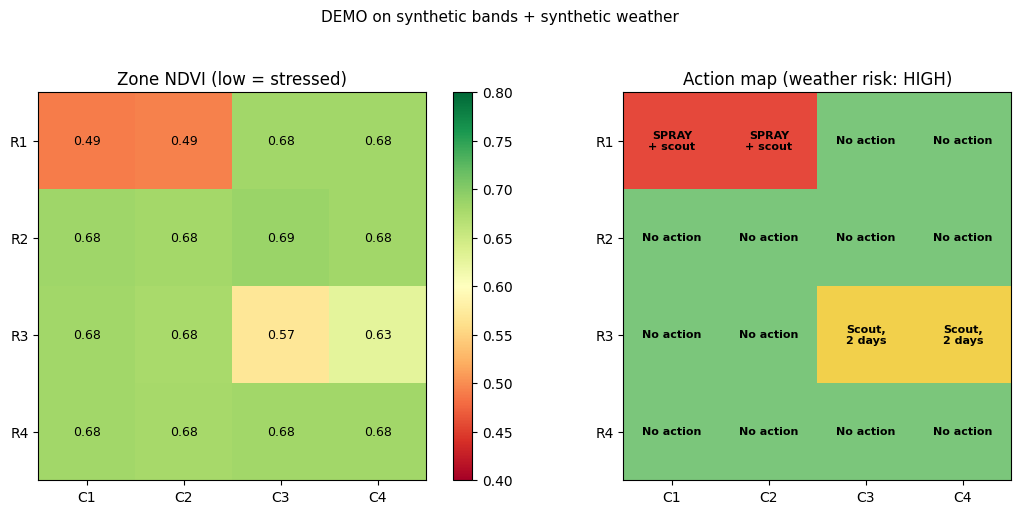

Zones needing spray now: 2/16  -> 88% of the field spared vs blanket spraying
Zone stress is NDVI-based; confirm on the ground / with the leaf classifier before treating.


In [22]:
import sys, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
sys.path.insert(0, 'src')
from vegetation_indices import ndvi, zone_means
from risk_forecast import make_data, build_xy

# ---------- 1. Field-level WEATHER risk (Random Forest from risk_forecast.py, synthetic weather) ----------
X_raw, fav = make_data(); X, y = build_xy(X_raw, fav)
n = len(X); a, b = int(n*0.64), int(n*0.80)
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                            min_samples_leaf=3, random_state=0).fit(X[:a], y[:a])
pv = rf.predict_proba(X[a:b])[:, 1]
th = max(np.linspace(0.05, 0.70, 27), key=lambda t: f1_score(y[a:b], pv >= t, zero_division=0))
p_test = rf.predict_proba(X[b:])[:, 1]
day = b + int(p_test.argmax())          # demo date: the most blight-favourable day in the test period
p = rf.predict_proba(X[day:day+1])[0, 1]
weather_high = p >= th
print(f"Weather risk for next 5 days: {p:.2f} (alert threshold {th:.2f}) -> {'HIGH' if weather_high else 'LOW'}")

# ---------- 2. Synthetic multispectral field (stand-in for a drone survey) ----------
rng = np.random.RandomState(1)
nir = rng.uniform(0.45, 0.55, (80, 80)); red = rng.uniform(0.07, 0.12, (80, 80))
nir[:20, :40] *= 0.55          # severe stress patch
nir[40:60, 40:70] *= 0.70      # mild stress patch
nd_map = ndvi(nir, red)
zones = zone_means(nd_map, 4, 4)
stress = (np.median(zones) - zones) / np.median(zones)    # relative NDVI drop vs field median

# ---------- 3. Zone-wise advice (rule-based) ----------
LEVEL = np.where(stress > 0.20, 2, np.where(stress > 0.08, 1, 0))   # 0 healthy, 1 watch, 2 stressed
def advice(level):
    if level == 2 and weather_high: return "SPRAY + scout"
    if level == 2:                  return "Scout, spray if blight"
    if level == 1 and weather_high: return "Scout, 2 days"
    if level == 1:                  return "Monitor"
    return "No action"
ACT = np.vectorize(advice)(LEVEL)

# ---------- 4. Plot ----------
fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
im = ax[0].imshow(zones, cmap="RdYlGn", vmin=0.4, vmax=0.8)
ax[0].set_title("Zone NDVI (low = stressed)"); plt.colorbar(im, ax=ax[0], fraction=0.046)
for r in range(4):
    for c in range(4): ax[0].text(c, r, f"{zones[r,c]:.2f}", ha="center", va="center", fontsize=9)
ax[1].imshow(LEVEL, cmap=ListedColormap(["#7bc67b", "#f2d04b", "#e5483b"]), vmin=0, vmax=2)
ax[1].set_title(f"Action map (weather risk: {'HIGH' if weather_high else 'LOW'})")
for r in range(4):
    for c in range(4): ax[1].text(c, r, ACT[r, c].replace(", ", ",\n").replace(" + ", "\n+ "), ha="center", va="center", fontsize=8, fontweight="bold")
for a_ in ax:
    a_.set_xticks(range(4)); a_.set_yticks(range(4))
    a_.set_xticklabels([f"C{i+1}" for i in range(4)]); a_.set_yticklabels([f"R{i+1}" for i in range(4)])
plt.suptitle("DEMO on synthetic bands + synthetic weather", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.95]); plt.savefig("outputs/field_action_map.png", dpi=150); plt.show()

spray = int((LEVEL == 2).sum() if weather_high else 0)
print(f"Zones needing spray now: {spray}/16  -> {100*(16-spray)/16:.0f}% of the field spared vs blanket spraying")
print("Zone stress is NDVI-based; confirm on the ground / with the leaf classifier before treating.")

In [9]:
!python src/train.py --data_dir data --model efficientnet_b0 --epochs 2

classes=['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']  train=1506 val=323 test=323  device=cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100% 20.5M/20.5M [00:00<00:00, 125MB/s] 
epoch 1/2  loss=0.1635  val_acc=0.9752  val_macro_recall=0.9822
epoch 2/2  loss=0.0448  val_acc=0.9938  val_macro_recall=0.9833
                       precision    recall  f1-score   support

Potato___Early_blight       0.99      1.00      1.00       150
 Potato___Late_blight       0.99      0.99      0.99       150
     Potato___healthy       1.00      0.91      0.95        23

             accuracy                           0.99       323
            macro avg       0.99      0.97      0.98       323
         weighted avg       0.99      0.99      0.99       323



In [11]:
!python src/train.py --data_dir data --model efficientnet_b0 --epochs 100 --patience 10

classes=['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']  train=1506 val=323 test=323  device=cuda
epoch 1/100  loss=0.1635  val_acc=0.9752  val_macro_recall=0.9822
epoch 2/100  loss=0.0448  val_acc=0.9938  val_macro_recall=0.9833
epoch 3/100  loss=0.1006  val_acc=1.0000  val_macro_recall=1.0000
epoch 4/100  loss=0.0346  val_acc=0.9969  val_macro_recall=0.9978
epoch 5/100  loss=0.0478  val_acc=1.0000  val_macro_recall=1.0000
epoch 6/100  loss=0.0175  val_acc=1.0000  val_macro_recall=1.0000
epoch 7/100  loss=0.0602  val_acc=0.9969  val_macro_recall=0.9978
epoch 8/100  loss=0.0831  val_acc=1.0000  val_macro_recall=1.0000
epoch 9/100  loss=0.0348  val_acc=1.0000  val_macro_recall=1.0000
epoch 10/100  loss=0.0223  val_acc=1.0000  val_macro_recall=1.0000
epoch 11/100  loss=0.0245  val_acc=1.0000  val_macro_recall=1.0000
epoch 12/100  loss=0.0110  val_acc=0.9969  val_macro_recall=0.9978
epoch 13/100  loss=0.0116  val_acc=1.0000  val_macro_recall=1.0000
Early stopping at 

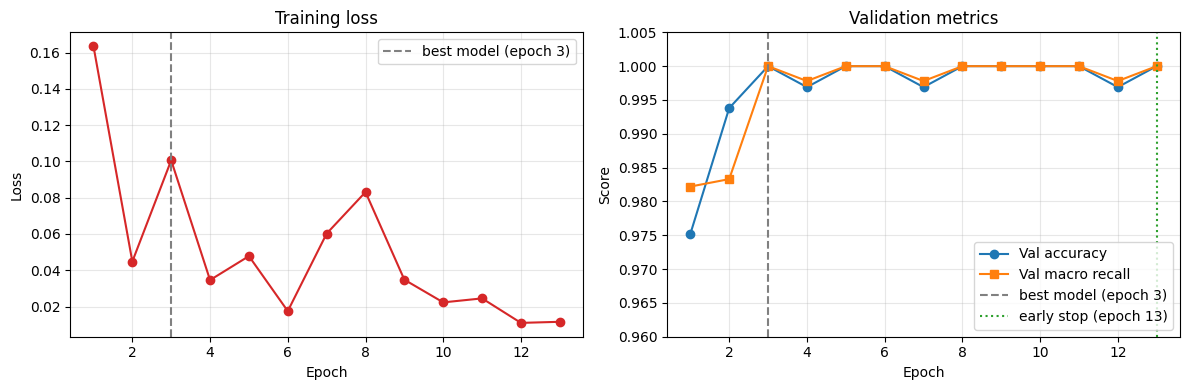

In [18]:
import matplotlib.pyplot as plt

# aapke training log se (13 epochs)
loss       = [0.1635,0.0448,0.1006,0.0346,0.0478,0.0175,0.0602,0.0831,0.0348,0.0223,0.0245,0.0110,0.0116]
val_acc    = [0.9752,0.9938,1.0,0.9969,1.0,1.0,0.9969,1.0,1.0,1.0,1.0,0.9969,1.0]
val_recall = [0.9822,0.9833,1.0,0.9978,1.0,1.0,0.9978,1.0,1.0,1.0,1.0,0.9978,1.0]
ep = list(range(1, len(loss) + 1))
best = 3   # best_model.pt isi epoch ka hai (pehli baar recall 1.0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(ep, loss, marker='o', color='tab:red')
ax[0].axvline(best, ls='--', color='gray', label=f'best model (epoch {best})')
ax[0].set_title('Training loss'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss')
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(ep, val_acc, marker='o', label='Val accuracy')
ax[1].plot(ep, val_recall, marker='s', label='Val macro recall')
ax[1].axvline(best, ls='--', color='gray', label=f'best model (epoch {best})')
ax[1].axvline(13, ls=':', color='tab:green', label='early stop (epoch 13)')
ax[1].set_ylim(0.96, 1.005)
ax[1].set_title('Validation metrics'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Score')
ax[1].legend(loc='lower right'); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/training_curves.png', dpi=150)
plt.show()

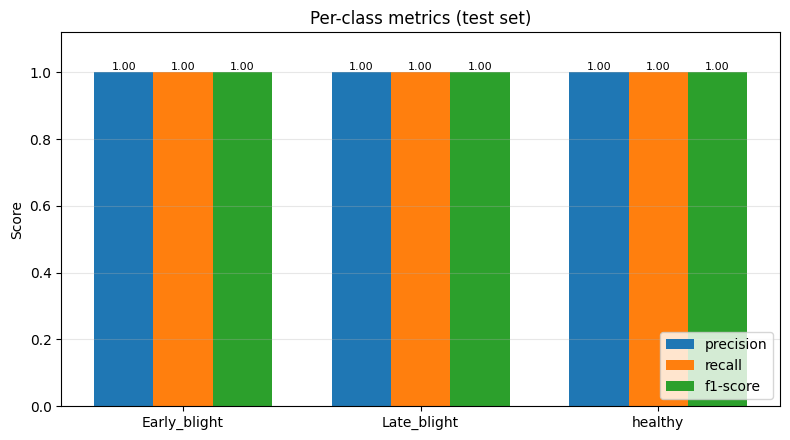

In [19]:
import json
import numpy as np
import matplotlib.pyplot as plt

m = json.load(open('outputs/metrics.json'))
classes = m['classes']
names = [c.split('___')[-1] for c in classes]
x = np.arange(len(classes)); w = 0.25

fig, ax = plt.subplots(figsize=(8, 4.5))
for k, key in enumerate(['precision', 'recall', 'f1-score']):
    vals = [m['report'][c][key] for c in classes]
    bars = ax.bar(x + (k - 1) * w, vals, w, label=key)
    ax.bar_label(bars, fmt='%.2f', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylim(0, 1.12); ax.set_ylabel('Score')
ax.set_title('Per-class metrics (test set)')
ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/class_metrics.png', dpi=150)
plt.show()

saved outputs/gradcam_examples.png


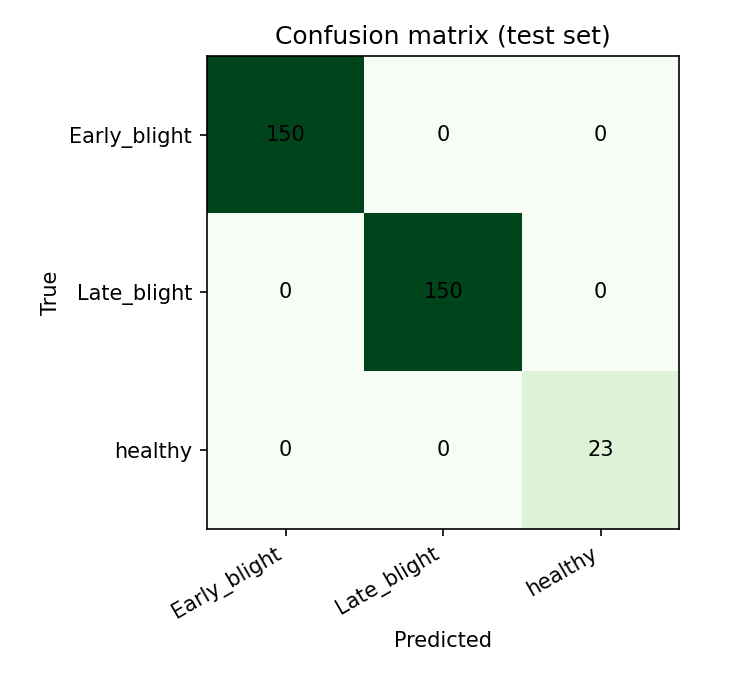

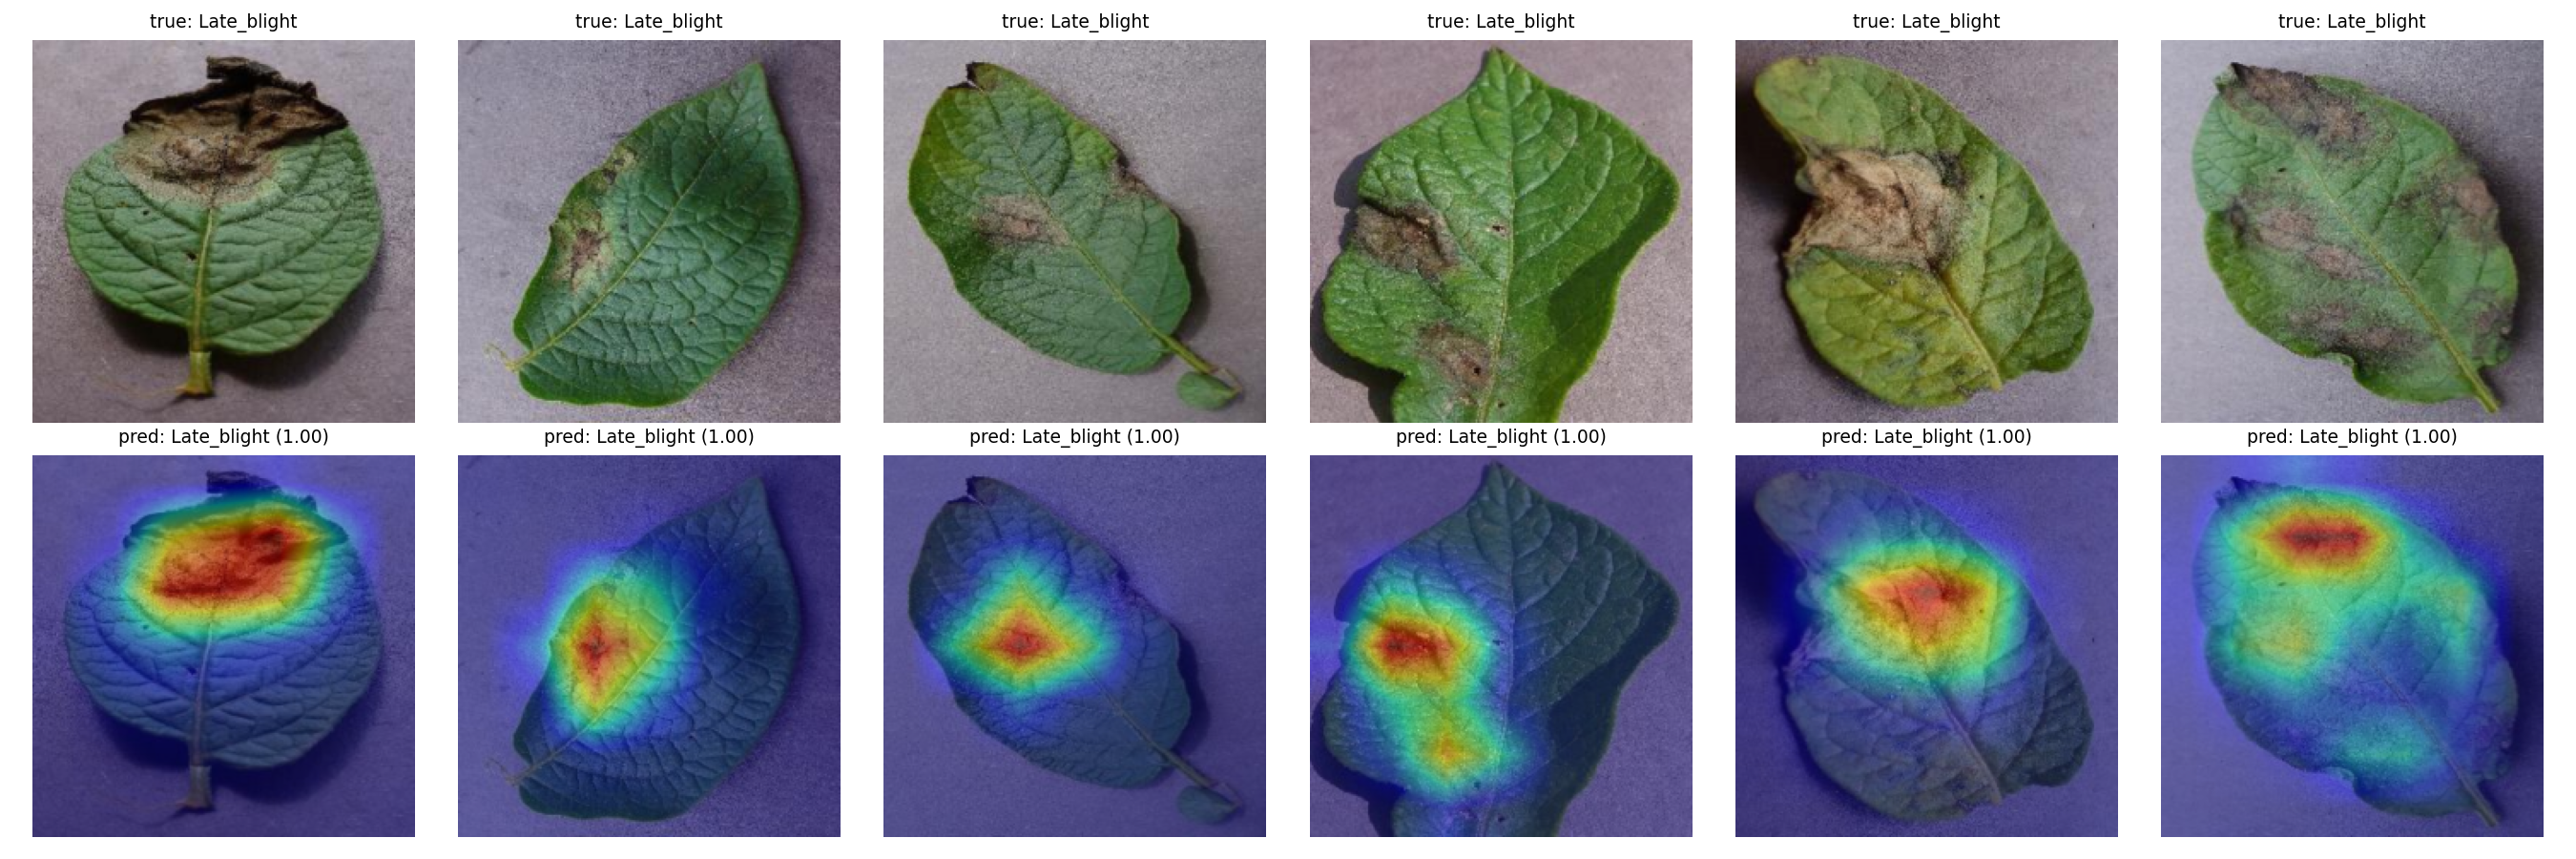

In [12]:
!python src/gradcam.py --data_dir data --model efficientnet_b0
from IPython.display import Image, display
display(Image('outputs/confusion_matrix.png'))
display(Image('outputs/gradcam_examples.png'))

In [17]:
!python src/vegetation_indices.py

NDVI zone means:
 [[0.51 0.51 0.67 0.67]
 [0.51 0.51 0.67 0.67]
 [0.68 0.67 0.67 0.67]
 [0.66 0.66 0.67 0.67]]


In [16]:
!python src/risk_forecast.py

high-risk share: train=0.13 val=0.18 test=0.10
chosen threshold (from validation) = 0.22
              precision    recall  f1-score   support

    low risk       0.97      0.82      0.89       265
   high risk       0.31      0.75      0.44        28

    accuracy                           0.82       293
   macro avg       0.64      0.79      0.66       293
weighted avg       0.91      0.82      0.85       293

